In [2]:
%%writefile ../src/utils.py
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

TARGET = "MSFT_next_week_ret"


def load_split(path, test_frac=0.2):
    """Chronological split: first 80% of weeks train, last 20% test. No shuffling."""
    df = pd.read_csv(path, index_col=0, parse_dates=True).sort_index()
    split = int(len(df) * (1 - test_frac))
    train, test = df.iloc[:split], df.iloc[split:]
    return (train.drop(columns=TARGET), test.drop(columns=TARGET),
            train[TARGET], test[TARGET])


def evaluate(y_true, y_pred, y_train_mean, name="model"):
    """Same metrics for every model."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    # Out-of-sample R2 measured against the training-mean forecast
    r2_oos = 1 - np.sum((y_true - y_pred) ** 2) / np.sum((y_true - y_train_mean) ** 2)
    dir_acc = np.mean((y_true > 0) == (y_pred > 0))
    return {"model": name, "RMSE": rmse, "MAE": mae, "R2": r2,
            "R2_OOS": r2_oos, "DirAcc": dir_acc}

Writing ../src/utils.py


In [4]:
import sys
sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import load_split, evaluate

paths = {
    "base": "../data/dataset_base.csv",
    "tech": "../data/dataset_with_technicals.csv",
}

for k, p in paths.items():
    X_tr, X_te, y_tr, y_te = load_split(p)
    print(f"[{k}] features={X_tr.shape[1]}  train={len(X_tr)} "
          f"({X_tr.index[0].date()} to {X_tr.index[-1].date()})  "
          f"test={len(X_te)} ({X_te.index[0].date()} to {X_te.index[-1].date()})")
    print(f"      test: share of up-weeks = {(y_te > 0).mean():.3f}, std = {y_te.std():.4f}")

[base] features=40  train=696 (2010-02-12 to 2023-06-09)  test=175 (2023-06-16 to 2026-10-16)
      test: share of up-weeks = 0.520, std = 0.0368
[tech] features=45  train=692 (2010-03-26 to 2023-06-23)  test=173 (2023-06-30 to 2026-10-16)
      test: share of up-weeks = 0.520, std = 0.0369


In [5]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

results = []

for k, p in paths.items():
    X_tr, X_te, y_tr, y_te = load_split(p)
    mu = y_tr.mean()

    # 1. Naive baselines
    results.append({**evaluate(y_te, np.full(len(y_te), mu), mu, "Train mean"), "data": k})
    results.append({**evaluate(y_te, np.zeros(len(y_te)), mu, "Zero forecast"), "data": k})

    # 2. Linear regression (scaler is fit on training data only, inside the pipeline)
    lin = Pipeline([("scale", StandardScaler()), ("lr", LinearRegression())])
    lin.fit(X_tr, y_tr)
    results.append({**evaluate(y_te, lin.predict(X_te), mu, "Linear regression"), "data": k})

    # 3. Ridge, tuned with time-ordered cross-validation on the training set only
    ridge = Pipeline([("scale", StandardScaler()), ("ridge", Ridge())])
    grid = GridSearchCV(
        ridge,
        {"ridge__alpha": np.logspace(-1, 4, 20)},
        cv=TimeSeriesSplit(n_splits=5),
        scoring="neg_root_mean_squared_error",
    )
    grid.fit(X_tr, y_tr)
    print(f"[{k}] best Ridge alpha = {grid.best_params_['ridge__alpha']:.2f}")
    results.append({**evaluate(y_te, grid.predict(X_te), mu, "Ridge"), "data": k})

res = pd.DataFrame(results).set_index(["data", "model"])
print(res.round(4))

[base] best Ridge alpha = 2976.35
[tech] best Ridge alpha = 2976.35
                          RMSE     MAE      R2  R2_OOS  DirAcc
data model                                                    
base Train mean         0.0367  0.0260 -0.0012  0.0000  0.5200
     Zero forecast      0.0368  0.0258 -0.0078 -0.0065  0.4800
     Linear regression  0.0364  0.0265  0.0167  0.0179  0.4514
     Ridge              0.0366  0.0260  0.0060  0.0072  0.5086
tech Train mean         0.0369  0.0260 -0.0010  0.0000  0.5202
     Zero forecast      0.0370  0.0259 -0.0080 -0.0071  0.4798
     Linear regression  0.0366  0.0268  0.0153  0.0162  0.4509
     Ridge              0.0368  0.0262  0.0023  0.0033  0.5145


In [1]:
print("kernel works")
import os
print(os.getcwd())
print(os.path.exists("../src/utils.py"), os.path.exists("../data/dataset_base.csv"))

kernel works
C:\Users\Gopya\msft-stock-prediction\notebooks
False True


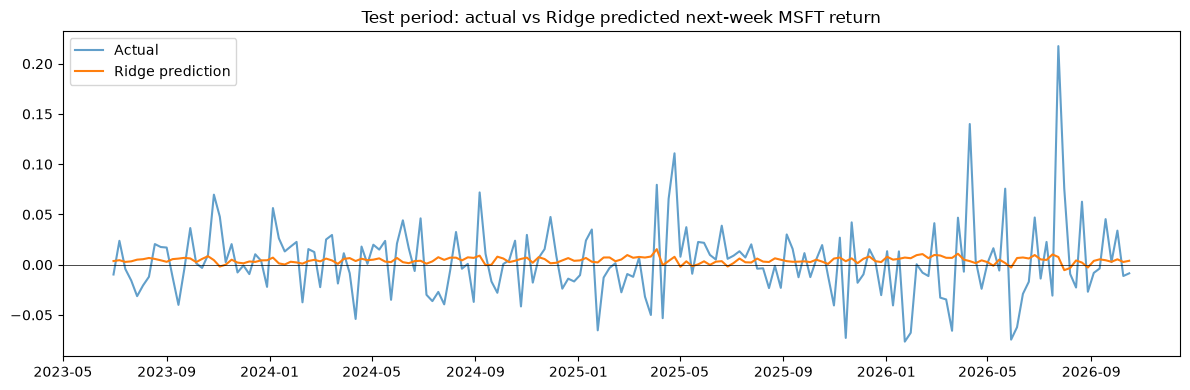

In [8]:
import os
os.makedirs("../results", exist_ok=True)
os.makedirs("../figures", exist_ok=True)
res.to_csv("../results/baseline_results.csv")

# Predicted vs actual for the Ridge model on the technicals dataset
# (`grid` holds the last fitted model, which is the "tech" one)
X_tr, X_te, y_tr, y_te = load_split(paths["tech"])
pred = grid.predict(X_te)

plt.figure(figsize=(12, 4))
plt.plot(y_te.index, y_te.values, label="Actual", alpha=0.7)
plt.plot(y_te.index, pred, label="Ridge prediction")
plt.axhline(0, color="k", lw=0.5)
plt.title("Test period: actual vs Ridge predicted next-week MSFT return")
plt.legend()
plt.tight_layout()
plt.savefig("../figures/07_ridge_pred_vs_actual.png", dpi=150)
plt.show()